<a href="https://colab.research.google.com/github/Wejdan-b/customer-churn-prediction/blob/main/customer_churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
print(pd.__version__)


2.2.3


In [2]:
import pandas as pd

In [3]:
print(pd.__version__)


2.2.3


In [4]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print(df.shape)
print(df.columns)

(7043, 21)
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


In [6]:
df['Churn'].head()


,Churn
0,No
1,No
2,Yes
3,No
4,Yes


In [7]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


## Data Cleaning

| # | الخطوة | الكود | السبب | النتيجة |
|---|---|---|---|---|
| 1 | فحص أنواع البيانات | `df.dtypes` | للتأكد أن كل عمود مخزّن بالنوع المناسب لمعناه | `TotalCharges` مخزّن كـ `object` بدل `float64` |
| 2 | البحث عن القيم غير الرقمية | `df[df['TotalCharges'] == ' ']` | للتحقق من سبب تحويل العمود إلى نص بدل التخمين | 11 عميلًا قيمتهم مسافة، وكلهم `tenure = 0` |
| 3 | تعويض المسافات | `replace(' ', 0.0)` | عملاء جدد لم يدفعوا بعد، فالقيمة الحقيقية صفر. التعويض بدل الحذف للحفاظ على عملاء حقيقيين | لا توجد مسافات في العمود |
| 4 | تحويل النوع | `astype(float)` | لإجراء العمليات الحسابية واستخدامه في النموذج. يأتي بعد التعويض لأن المسافة لا تتحول لرقم | العمود أصبح `float64` |
| 5 | فحص القيم المفقودة | `df.isnull().sum()` | أغلب النماذج لا تقبل خانات فارغة | 0 في كل الأعمدة |
| 6 | فحص الصفوف المكررة | `df.duplicated().sum()` | الصف المكرر يُحسب مرتين فيؤثر على الأنماط والنموذج | 0 صفوف مكررة |

In [8]:
blank = df['TotalCharges'] == ' '
df[blank]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [9]:
df['TotalCharges'] = df['TotalCharges'].replace(' ', 0.0)
df['TotalCharges'] = df['TotalCharges'].astype(float)
df['TotalCharges'].dtype

dtype('float64')

In [10]:
df.isnull().sum()


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [11]:
df.duplicated().sum()


np.int64(0)

In [12]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [13]:
1869 / 7043

0.2653698707936959

In [14]:
df['Churn'].value_counts(normalize=True)


,proportion
Churn,
No,0.73463
Yes,0.26537


In [15]:
pd.crosstab(df['Contract'], df['Churn'], normalize='index')


Churn,No,Yes
Contract,,
Month-to-month,0.572903,0.427097
One year,0.887305,0.112695
Two year,0.971681,0.028319


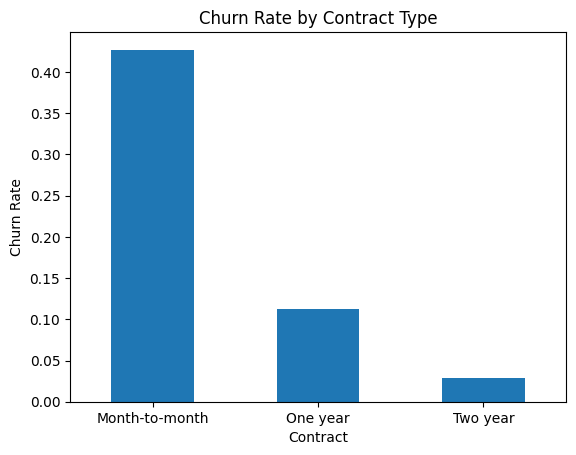

In [16]:
import matplotlib.pyplot as plt

contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index')
contract_churn['Yes'].plot(kind='bar')
plt.title('Churn Rate by Contract Type')
plt.ylabel('Churn Rate')
plt.xticks(rotation=0)
plt.show()

يغادر 43% من عملاء العقد الشهري، مقابل 11% لعقد السنة و3% فقط لعقد السنتين، مما يجعل عملاء العقد الشهري الفئة الأعلى خطرًا. نقترح تجربة عروض موجّهة لهم، مثل خصم عند الترقية لعقد سنوي أو فترة تجربة مجانية، ثم قياس أثرها على نسبة المغادرة.

In [17]:
df['tenure_group'] = pd.cut(df['tenure'],
                            bins=[0, 12, 48, 72],
                            labels=['0-12', '13-48', '49-72'],
                            include_lowest=True)

pd.crosstab(df['tenure_group'], df['Churn'], normalize='index')

Churn,No,Yes
tenure_group,,
0-12,0.525618,0.474382
13-48,0.763560,0.236440
49-72,0.904868,0.095132


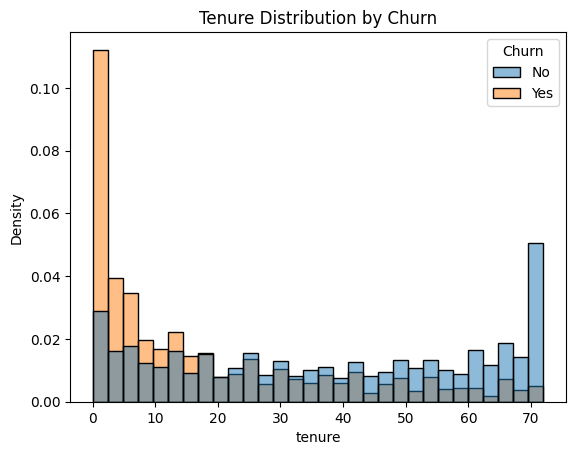

In [18]:
import seaborn as sns

sns.histplot(data=df, x='tenure', hue='Churn',
             stat='density', common_norm=False, bins=30)
plt.title('Tenure Distribution by Churn')
plt.show()

المغادرة تتركز بشكل كبير في بداية الاشتراك: 47% من العملاء في سنتهم الأولى يغادرون، مقابل 23% لمن تجاوزوا السنة، و9.5% فقط لمن بقوا أكثر من 4 سنوات. ويُظهر الرسم أن الأشهر القليلة الأولى تحديدًا هي الأعلى خطرًا، بينما يتكدّس العملاء المخلصون عند أطول مدد الاشتراك.

المقترح: تجربة برنامج ترحيب ومتابعة مكثفة للعملاء الجدد خلال سنتهم الأولى، وقياس أثره على نسبة المغادرة.

ملاحظة: مدة الاشتراك متداخلة مع نوع العقد، إذ إن أغلب العملاء الجدد على عقود شهرية، لذلك لا يمكن فصل تأثير العاملين من هذا الرسم وحده.

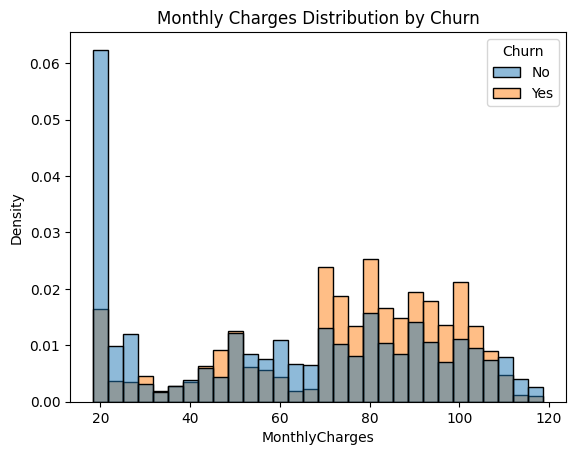

In [19]:
sns.histplot(data=df, x='MonthlyCharges', hue='Churn',
             stat='density', common_norm=False, bins=30)
plt.title('Monthly Charges Distribution by Churn')
plt.show()

Insight: الفاتورة الشهرية ونوع الإنترنت والمغادرة

العملاء الذين غادروا تتركز فواتيرهم في النطاق المرتفع (70 إلى 105 دولارات تقريبًا)، بينما يتكدّس العملاء الباقون عند الفواتير المنخفضة (حوالي 20 دولارًا)، وهم غالبًا عملاء بدون إنترنت (متوسط فاتورتهم 21 دولارًا ونسبة مغادرتهم 7.4% فقط).

وبالتعمق، تبيّن أن عملاء Fiber optic، وهم الأعلى فاتورةً (متوسط 91.5 دولارًا)، يغادرون بنسبة 41.9%، أي ضعف عملاء DSL (19%) تقريبًا.

المقترح: دراسة أسباب مغادرة عملاء Fiber optic تحديدًا، مثل استبيان للعملاء المغادرين أو مقارنة الأسعار بالمنافسين، قبل اتخاذ أي إجراء، لأن البيانات تُظهر الارتباط ولا تحدد السبب.

In [20]:
df.groupby('InternetService')['MonthlyCharges'].mean()

,MonthlyCharges
InternetService,
DSL,58.102169
Fiber optic,91.500129
No,21.079194


In [21]:
pd.crosstab(df['InternetService'], df['Churn'], normalize='index')

Churn,No,Yes
InternetService,,
DSL,0.810409,0.189591
Fiber optic,0.581072,0.418928
No,0.925950,0.074050
